## Импорт библиотек и датафрейма

In [1]:
from collections import Counter
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from sklearn.model_selection import train_test_split

RANDOM_STATE = 21
TEST_SIZE = 0.25

DATA_PATH = 'data/train.json'

df = pd.read_json(DATA_PATH)
print(f"Размер датасета: {df.shape}")
display(df.head(3))

Размер датасета: (49352, 15)


,bathrooms,bedrooms,building_id,created,description,display_address,features,latitude,listing_id,longitude,manager_id,photos,price,street_address,interest_level
4,1.0,1,8579a0b0d54db803821a35a4a615e97a,2016-06-16 05:55:27,Spacious 1 Bedroom 1 Bathroom in Williamsburg!...,145 Borinquen Place,"[Dining Room, Pre-War, Laundry in Building, Di...",40.7108,7170325,-73.9539,a10db4590843d78c784171a107bdacb4,[https://photos.renthop.com/2/7170325_3bb5ac84...,2400,145 Borinquen Place,medium
6,1.0,2,b8e75fc949a6cd8225b455648a951712,2016-06-01 05:44:33,BRAND NEW GUT RENOVATED TRUE 2 BEDROOMFind you...,East 44th,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7513,7092344,-73.9722,955db33477af4f40004820b4aed804a0,[https://photos.renthop.com/2/7092344_7663c19a...,3800,230 East 44th,low
9,1.0,2,cd759a988b8f23924b5a2058d5ab2b49,2016-06-14 15:19:59,**FLEX 2 BEDROOM WITH FULL PRESSURIZED WALL**L...,East 56th Street,"[Doorman, Elevator, Laundry in Building, Laund...",40.7575,7158677,-73.9625,c8b10a317b766204f08e613cef4ce7a0,[https://photos.renthop.com/2/7158677_c897a134...,3495,405 East 56th Street,medium


In [2]:
df.info()

<class 'pandas.DataFrame'>
Index: 49352 entries, 4 to 124009
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   bathrooms        49352 non-null  float64
 1   bedrooms         49352 non-null  int64  
 2   building_id      49352 non-null  str    
 3   created          49352 non-null  str    
 4   description      49352 non-null  str    
 5   display_address  49352 non-null  str    
 6   features         49352 non-null  object 
 7   latitude         49352 non-null  float64
 8   listing_id       49352 non-null  int64  
 9   longitude        49352 non-null  float64
 10  manager_id       49352 non-null  str    
 11  photos           49352 non-null  object 
 12  price            49352 non-null  int64  
 13  street_address   49352 non-null  str    
 14  interest_level   49352 non-null  str    
dtypes: float64(3), int64(3), object(2), str(7)
memory usage: 6.0+ MB


## Обработка выбросов: получаем `df_clean`

Размер датасета до обработки выбросов: (49352, 15)
Размер датасета после обработки выбросов: (48379, 15)


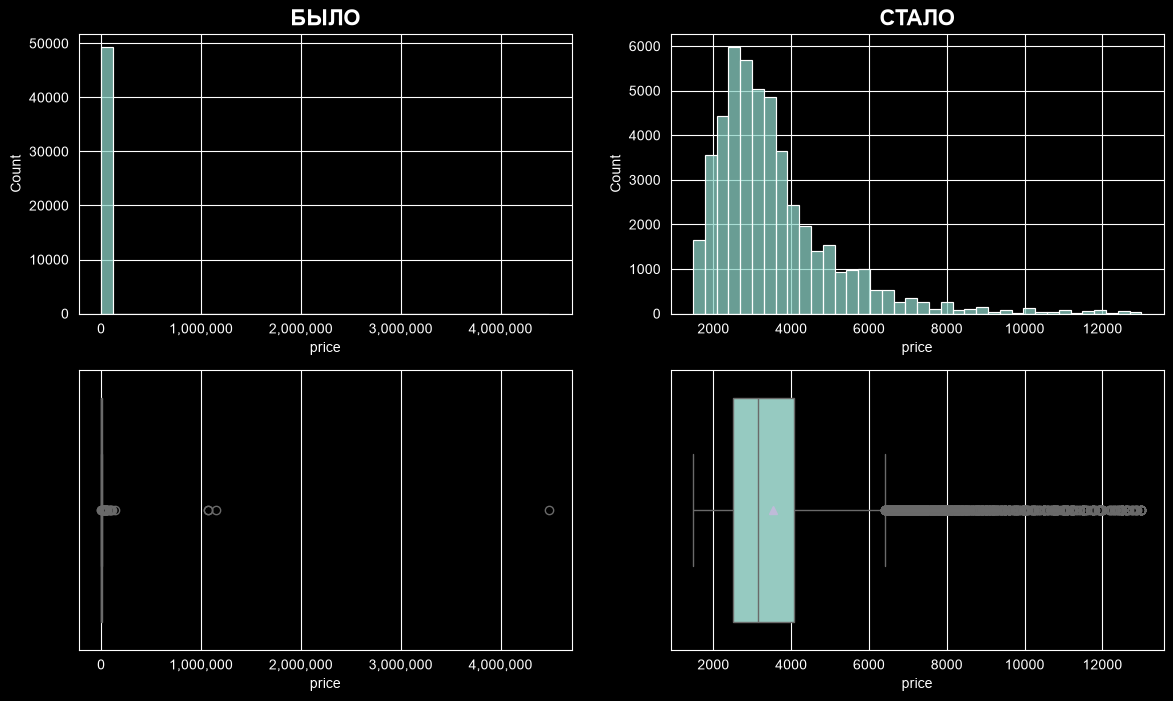

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sns.histplot(df['price'], bins=38, ax=axes[0, 0])
sns.boxplot(x=df['price'], ax=axes[1, 0])

print(f"Размер датасета до обработки выбросов: {df.shape}")
df_clean = df[df["price"].between(df["price"].quantile(0.01), df["price"].quantile(0.99), inclusive="both")].copy()
print(f"Размер датасета после обработки выбросов: {df_clean.shape}")

sns.histplot(df_clean['price'], bins=38, ax=axes[0, 1])
sns.boxplot(x=df_clean['price'], ax=axes[1, 1], showmeans=True)

axes[0, 0].set_title('БЫЛО', fontsize=16, fontweight='bold')
axes[0, 1].set_title('СТАЛО', fontsize=16, fontweight='bold')
axes[0, 0].xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
axes[1, 0].xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))

plt.show()

## Разбиение на `train_df` и `test_df`

In [4]:
train_df, test_df = train_test_split(
    df_clean,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    )

print(f"Размер train_df: {train_df.shape}")
print(f"Размер test_df: {test_df.shape}")

Размер train_df: (36284, 15)
Размер test_df: (12095, 15)


## Выбор датафрейма для дальнейшей работы

In [5]:
CURRENT_MODE = 'df2'  # <== МЕНЯТЬ ЗДЕСЬ!

config = {

    'df1': {
        'df': train_df,  # - 0,75 от очищенного от выбросов по цене датафрейма
        'df_filename': 'train_df_processed_0.75'
        },
    'df2': {
        'df': df_clean,  # - весь очищенный от выбросов по цене датафрейм
        'df_filename': 'train_df_processed_full'
        }
    }

df = config[CURRENT_MODE]['df']
df_filename = config[CURRENT_MODE]['df_filename']

In [6]:
print("Сумма по первым двум столбцам:")
sums_first_two = df.iloc[:, :2].sum()
print(sums_first_two)

# Считаем сумму по столбцу 'price'
total_price = df['price'].sum()
print(f"Общая сумма по столбцу price: {total_price}")

Сумма по первым двум столбцам:
bathrooms    57822.5
bedrooms     74244.0
dtype: float64
Общая сумма по столбцу price: 171195714


## Кодируем признак `Interest_level`

In [7]:
# Кодируем категории числами: low, medium и high превращаются в 0, 1 и 2.
interest_level_map = {"low": 0, "medium": 1, "high": 2}
df["interest_level_encoded"] = df["interest_level"].map(interest_level_map)
print(df["interest_level"].value_counts())
print(df["interest_level_encoded"].value_counts())
df = df.rename(columns={'interest_level_encoded': 'interest'})

interest_level
low       33697
medium    11116
high       3566
Name: count, dtype: int64
interest_level_encoded
0    33697
1    11116
2     3566
Name: count, dtype: int64


## Получение признаков из `features`

In [8]:
def clean_feature_name(value: str) -> str:
    return (
        str(value)
        .replace("[", "")
        .replace("]", "")
        .replace("'", "")
        .replace('"', "")
        .replace(" ", "")
        .strip()
    )


all_train_features = []
for features in df["features"]:
    for feature in features:
        all_train_features.append(clean_feature_name(feature))

feature_counter = Counter(all_train_features)
feature_list = [name for name, _ in feature_counter.most_common(20)]
# Выводим количество каждого признака, используя feature_list
print("\nКоличество каждого признака:")
for name in feature_list:
    # feature_counter работает как словарь, поэтому мы можем просто обратиться к нему по ключу
    print(f"{name}: {feature_counter[name]}")


Количество каждого признака:
Elevator: 25398
HardwoodFloors: 23159
CatsAllowed: 23148
DogsAllowed: 21662
Doorman: 20497
Dishwasher: 20095
NoFee: 17806
LaundryinBuilding: 16093
FitnessCenter: 13000
Pre-War: 8978
LaundryinUnit: 8448
RoofDeck: 6423
OutdoorSpace: 5137
DiningRoom: 4901
HighSpeedInternet: 4225
Balcony: 2898
SwimmingPool: 2648
LaundryInBuilding: 2565
NewConstruction: 2507
Terrace: 2179


## Создание бинарных признаков

In [9]:
print("До:", df.shape)

df["_clean_features"] = df["features"].apply(
    lambda x: [clean_feature_name(item) for item in x]
    if isinstance(x, (list, np.ndarray, pd.Series))
    else []
    )

for feature in feature_list:
    df[feature] = df["_clean_features"].apply(
        lambda x: int(feature in x)
        )

df = df.drop(columns=["_clean_features"])

print("После:", df.shape)

До: (48379, 16)
После: (48379, 36)


## Выбор нужных столбцов

In [10]:
feature_list.remove('LaundryInBuilding')
df_columns = ['bathrooms', 'bedrooms', 'price', 'interest', 'created'] + feature_list  # Имена всех столбцов датафрейма
numeric_features = df_columns.copy()
numeric_features.remove('created')  # Список только числовых столбцов
print(df_columns, numeric_features)
df["created"] = pd.to_datetime(df["created"])
df = df[df_columns]


['bathrooms', 'bedrooms', 'price', 'interest', 'created', 'Elevator', 'HardwoodFloors', 'CatsAllowed', 'DogsAllowed', 'Doorman', 'Dishwasher', 'NoFee', 'LaundryinBuilding', 'FitnessCenter', 'Pre-War', 'LaundryinUnit', 'RoofDeck', 'OutdoorSpace', 'DiningRoom', 'HighSpeedInternet', 'Balcony', 'SwimmingPool', 'NewConstruction', 'Terrace'] ['bathrooms', 'bedrooms', 'price', 'interest', 'Elevator', 'HardwoodFloors', 'CatsAllowed', 'DogsAllowed', 'Doorman', 'Dishwasher', 'NoFee', 'LaundryinBuilding', 'FitnessCenter', 'Pre-War', 'LaundryinUnit', 'RoofDeck', 'OutdoorSpace', 'DiningRoom', 'HighSpeedInternet', 'Balcony', 'SwimmingPool', 'NewConstruction', 'Terrace']


In [11]:
df.info()

<class 'pandas.DataFrame'>
Index: 48379 entries, 4 to 124009
Data columns (total 24 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   bathrooms          48379 non-null  float64       
 1   bedrooms           48379 non-null  int64         
 2   price              48379 non-null  int64         
 3   interest           48379 non-null  int64         
 4   created            48379 non-null  datetime64[us]
 5   Elevator           48379 non-null  int64         
 6   HardwoodFloors     48379 non-null  int64         
 7   CatsAllowed        48379 non-null  int64         
 8   DogsAllowed        48379 non-null  int64         
 9   Doorman            48379 non-null  int64         
 10  Dishwasher         48379 non-null  int64         
 11  NoFee              48379 non-null  int64         
 12  LaundryinBuilding  48379 non-null  int64         
 13  FitnessCenter      48379 non-null  int64         
 14  Pre-War            48

## Визуализация бинарных признаков

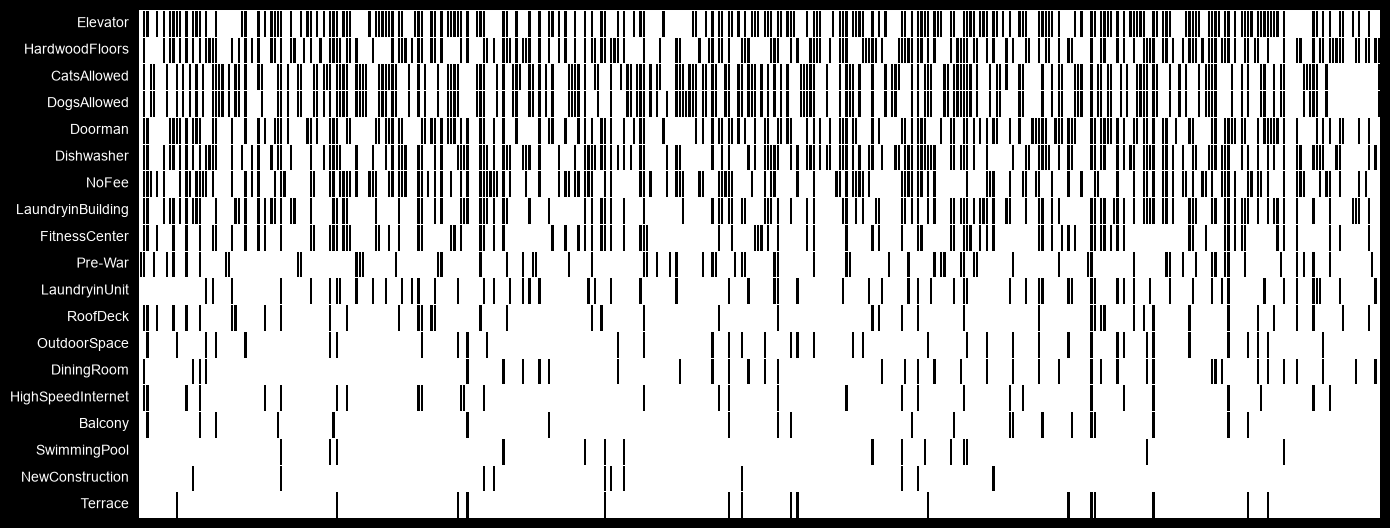

In [12]:
plt.figure(figsize=(14, 5.38))
feature_list_1 = ['Doorman', 'FitnessCenter']
sample_data = df[feature_list].sample(380).T
sns.heatmap(sample_data, cmap='Greys', cbar=False, linewidths=0.5)
plt.yticks(rotation=0, fontsize=10)
plt.xticks([])  # Убираем подписи на оси X
plt.tight_layout()
plt.show()

## Корреляционная матрица

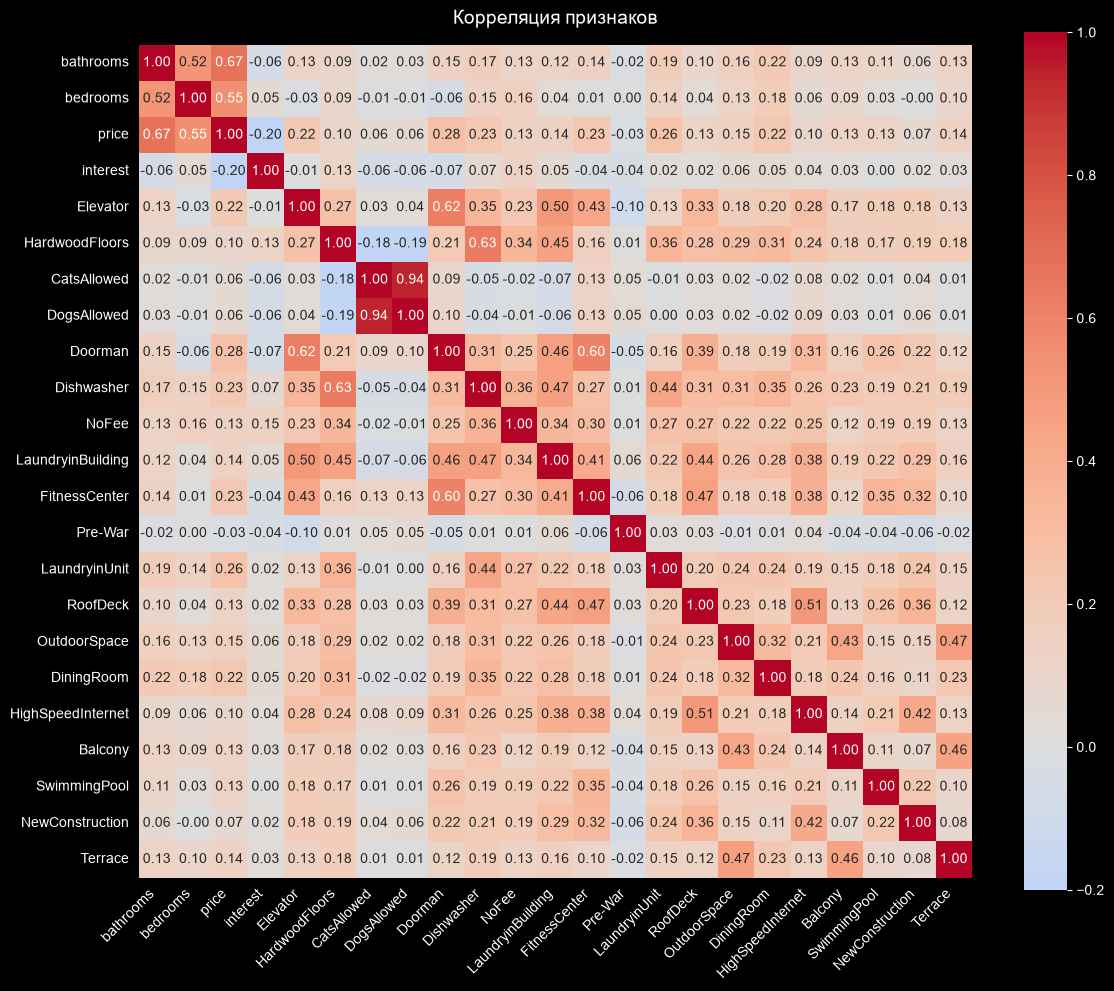

In [13]:
plt.figure(figsize=(12, 10))

corr_matrix = df[numeric_features].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True)

plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.title('Корреляция признаков', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

## Проверка по контрольным суммам

In [14]:
sums = df[numeric_features].sum()
print(sums)

bathrooms                57822.5
bedrooms                 74244.0
price                171195714.0
interest                 18248.0
Elevator                 25398.0
HardwoodFloors           23159.0
CatsAllowed              23148.0
DogsAllowed              21662.0
Doorman                  20497.0
Dishwasher               20095.0
NoFee                    17806.0
LaundryinBuilding        16093.0
FitnessCenter            13000.0
Pre-War                   8978.0
LaundryinUnit             8448.0
RoofDeck                  6423.0
OutdoorSpace              5137.0
DiningRoom                4901.0
HighSpeedInternet         4225.0
Balcony                   2898.0
SwimmingPool              2648.0
NewConstruction           2507.0
Terrace                   2179.0
dtype: float64


In [15]:
with pd.option_context('display.max_columns', None):
    display(train_df.sample(5))

,bathrooms,bedrooms,building_id,created,description,display_address,features,latitude,listing_id,longitude,manager_id,photos,price,street_address,interest_level
116706,1.0,1,0,2016-04-10 03:41:54,"Stunning, gut renovated 1 bedroom in a beautif...",Jane Street,"[Elevator, Laundry in Building, Hardwood Floors]",40.7381,6852481,-74.0026,f5b4f30a5e431fcea734cea1d5e740bb,[https://photos.renthop.com/2/6852481_56ff889b...,4075,1 Jane Street,low
34075,2.0,3,aed67db466854ec2aa5d249a032bc401,2016-06-05 03:17:30,Huge fully renovated 3 Bedroom 2 Bath apartmen...,E 47th St,"[Dining Room, Dishwasher, Hardwood Floors, No ...",40.7530,7113228,-73.9695,eb5a6c4c2eb6f3e2a085c477afd5a815,[https://photos.renthop.com/2/7113228_e5c93d00...,4200,301 E 47th St,high
117943,1.0,0,231c1bd2508bcd4250b9f9ace5380ecc,2016-04-21 13:05:20,Sunny and Delightful Junior 1BR Apartment In T...,162 Allen st.,[],40.7210,6908631,-73.9891,6bd71b013b6705f9b7f64dcf2af31c90,[https://photos.renthop.com/2/6908631_c81ded19...,2175,162 Allen st.,low
25275,1.0,0,73545829271240c1ebae5667f3811124,2016-06-21 03:15:02,Mint condition sunny studio with eastern expos...,77 West 55th Street,"[Garage, Doorman, Elevator, Cats Allowed, Dogs...",40.7630,7189178,-73.9778,10df52addfb8738904bf3d147b0dcf5a,[https://photos.renthop.com/2/7189178_a05fc5f2...,2650,77 West 55th Street,low
40755,1.0,2,7a4e86084d2514e208182c175e9c66a3,2016-06-02 05:31:17,PLEASE DO NOT MISS OUT ON THIS GORGEOUS MODERN...,East 35th Street,"[Elevator, Hardwood Floors, No Fee]",40.7463,7098557,-73.9773,30a7951cfc21240e8c46b2d079d292e5,[https://photos.renthop.com/2/7098557_34954921...,2900,201 East 35th Street,high


## Сохранение

In [16]:
df.to_json(f'data/{df_filename}.json', date_format='iso', orient='records', force_ascii=False)
df.to_csv(f'data/{df_filename}.csv', index=False)

## КОНЕЦ

In [17]:
from datetime import datetime

print("=" * 38, datetime.now(), 'jacquieb', sep="\n")

2026-10-11 12:35:39.399495
jacquieb
